# 15. Optimización multi-fidelidad: Successive Halving e Hyperband

La sección 3.3 del enunciado recomienda al menos un método que **elimine pronto las configuraciones poco
prometedoras** evaluándolas con un presupuesto parcial y reasigne lo ahorrado a las más competitivas. El
proyecto usa la multi-fidelidad en dos niveles:

1. **Entre combinaciones** (cap. 13.7): un tamizaje de baja fidelidad (5 evaluaciones, 2 pliegues) descartó
   20 combinaciones de clasificación antes de correrlas completas.
2. **Dentro de una búsqueda** (este capítulo): Successive Halving (Jamieson y Talwalkar, 2016) e Hyperband
   (Li et al., 2018) frente a Random Search, con XGBoost de regresión, el modelo más competitivo del benchmark.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Resultados de multifidelidad: Random Search, Successive Halving e Hyperband
from src import benchmark as bm, resultados_e2 as r2
D = pd.read_csv(r2.E2 / "multifidelidad.csv")
F = pd.read_csv(r2.E2 / "multifidelidad_resumen.csv")

## 15.1 Diseño

- **Fidelidad (recurso): número de árboles** de XGBoost, con R = 600 como recurso completo (el máximo del
  espacio del cap. 13.3). Es una buena medida de fidelidad porque (i) el costo de ajuste es lineal en el
  número de árboles, y (ii) en boosting el error con pocos árboles **suele** estar correlacionado con el
  error final, de modo que las configuraciones malas se descartan pronto. El supuesto (ii) se verifica en
  15.2, porque con learning rates bajos puede fallar. Los demás hiperparámetros (profundidad, learning rate,
  subsample, colsample,
  min_child_weight) se muestrean igual que en Random Search.
- **Factor de reducción η = 3.** En cada ronda se conserva el mejor tercio y se triplica el recurso. Es el
  valor recomendado por Li et al. (2018): con η = 2 habría más rondas (más sobrecosto y más decisiones con
  fidelidad baja); con η = 4 o más se descarta demasiado con una sola medición ruidosa.
- **Successive Halving:** 27 configuraciones con R/9 ≈ 66 árboles → 9 con 200 → 3 con 600. Costo:
  27/9 + 9/3 + 3 = **9 evaluaciones equivalentes** (una equivalente = una validación interna con 600 árboles).
- **Hyperband** (s_max = 2): tres brackets que reparten el riesgo de cortar demasiado pronto: s = 2 (el SH
  anterior), s = 1 (5 configuraciones con 200 → 1 con 600) y s = 0 (3 configuraciones con 600, sin corte).
  Costo ≈ **14,7 equivalentes**, casi igual al de Random Search.
- **Random Search:** 15 configuraciones con 600 árboles = **15 equivalentes** (el presupuesto del cap. 14).
- **Sin fuga y sin tocar la prueba:** la búsqueda usa la validación temporal interna (3 pliegues) sobre el
  entrenamiento **sin su último año**; la configuración ganadora de cada método se reentrena y se evalúa en
  ese último año (dic-2019 a nov-2020), que ningún método vio.

## 15.2 Resultados

In [3]:
# Tabla de costo y error de cada método
F2 = F[["metodo", "evaluaciones", "costo_equiv", "tiempo_s", "RMSLE_cv_mejor", "RMSLE_reserva"]].copy()
F2.columns = ["método", "configuraciones evaluadas (todas las fidelidades)", "costo (evaluaciones equivalentes)",
              "tiempo de búsqueda (s)", "mejor RMSLE interno", "RMSLE en el año reservado"]
eda.guardar_tabla(F2, "e2_multifidelidad.csv")
F2.round(4)

,método,configuraciones evaluadas (todas las fidelidades),costo (evaluaciones equivalentes),tiempo de búsqueda (s),mejor RMSLE interno,RMSLE en el año reservado
0,Hyperband,48,14.6667,35.1265,0.3584,0.3217
1,Random Search,15,15.0000,32.7897,0.3573,0.3216
2,Successive Halving,39,9.0000,21.2065,0.3598,0.3231


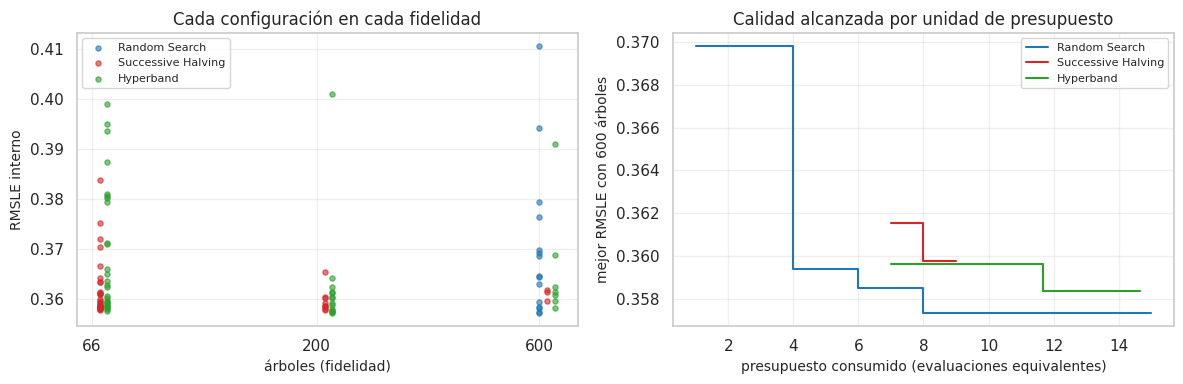

In [4]:
# Gráficos: error por fidelidad y mejor error frente al costo acumulado
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for metodo, c in zip(["Random Search", "Successive Halving", "Hyperband"], ["#1f77b4", "#d62728", "#2ca02c"]):
    g = D[D.metodo == metodo]
    axs[0].scatter(g.recurso * (1 + 0.04 * ["Random Search", "Successive Halving", "Hyperband"].index(metodo)), g.RMSLE_cv, s=14, alpha=0.6, color=c, label=metodo)
    g2 = g.reset_index(drop=True)
    acum = g2.costo_equiv.cumsum(); mejor = g2.where(g2.recurso == 600).RMSLE_cv.cummin().ffill()
    axs[1].step(acum, mejor, where="post", color=c, label=metodo)
axs[0].set_xscale("log"); axs[0].set_xticks([66, 200, 600]); axs[0].set_xticklabels(["66", "200", "600"])
axs[0].set_xlabel("árboles (fidelidad)"); axs[0].set_ylabel("RMSLE interno"); axs[0].set_title("Cada configuración en cada fidelidad")
axs[1].set_xlabel("presupuesto consumido (evaluaciones equivalentes)"); axs[1].set_ylabel("mejor RMSLE con 600 árboles")
axs[1].set_title("Calidad alcanzada por unidad de presupuesto")
for a in axs:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); eda.guardar_figura(fig, "e2_multifidelidad.png"); plt.show()

In [5]:
# Correlación entre fidelidades y lectura
f = F.set_index("metodo")
corr = D[(D.metodo != "Random Search")]
pares = corr.pivot_table(index=["metodo", "config"], columns="recurso", values="RMSLE_cv").dropna(subset=[66, 200]) if 66 in corr.recurso.values else None
rho = stats.spearmanr(pares[66], pares[200])[0] if pares is not None and len(pares) > 3 else np.nan
md(f"- **Costo.** Successive Halving gastó {f.loc['Successive Halving', 'costo_equiv']:.1f} evaluaciones equivalentes "
   f"({100 * f.loc['Successive Halving', 'costo_equiv'] / f.loc['Random Search', 'costo_equiv']:.0f} % del presupuesto de Random Search) "
   f"y exploró {int(f.loc['Successive Halving', 'evaluaciones'])} evaluaciones parciales sobre 27 configuraciones, casi el doble de "
   f"configuraciones que Random Search (15). Hyperband gastó {f.loc['Hyperband', 'costo_equiv']:.1f} equivalentes sobre 35 configuraciones.\n"
   f"- **Tiempo.** Random Search tardó {f.loc['Random Search', 'tiempo_s']:.0f} s, Successive Halving {f.loc['Successive Halving', 'tiempo_s']:.0f} s "
   f"e Hyperband {f.loc['Hyperband', 'tiempo_s']:.0f} s.\n"
   f"- **Calidad.** El mejor RMSLE interno fue {f.loc['Random Search', 'RMSLE_cv_mejor']:.4f} (Random), {f.loc['Successive Halving', 'RMSLE_cv_mejor']:.4f} "
   f"(SH) y {f.loc['Hyperband', 'RMSLE_cv_mejor']:.4f} (Hyperband); en el año reservado, {f.loc['Random Search', 'RMSLE_reserva']:.4f}, "
   f"{f.loc['Successive Halving', 'RMSLE_reserva']:.4f} y {f.loc['Hyperband', 'RMSLE_reserva']:.4f}. Las diferencias son de "
   f"milésimas: la multi-fidelidad llega a soluciones **cercanas** a las de Random Search con menos cómputo.\n"
   f"- **¿Es buena la fidelidad?** La correlación de Spearman entre el RMSLE con 66 árboles y con 200 árboles de las mismas "
   f"configuraciones es {rho:.2f}. "
   + ("Una correlación alta justifica cortar con 66 árboles." if rho > 0.6 else
      "Es **débil**: con 66 árboles y learning rates que pueden ser tan bajos como 0,01, el boosting está lejos de converger y el orden "
      "de las configuraciones con poca fidelidad dice poco del orden final. Por eso Successive Halving descartó configuraciones que "
      "habrían sido buenas y terminó con una algo peor. Dos arreglos naturales: subir el recurso mínimo (p. ej. R/3) o usar como "
      "recurso el número de árboles **escalado por el learning rate**. Hyperband, que incluye brackets sin corte temprano, es más "
      "robusto frente a una fidelidad pobre, y por eso quedó empatado con Random Search."))

- **Costo.** Successive Halving gastó 9.0 evaluaciones equivalentes (60 % del presupuesto de Random Search) y exploró 39 evaluaciones parciales sobre 27 configuraciones, casi el doble de configuraciones que Random Search (15). Hyperband gastó 14.7 equivalentes sobre 35 configuraciones.
- **Tiempo.** Random Search tardó 33 s, Successive Halving 21 s e Hyperband 35 s.
- **Calidad.** El mejor RMSLE interno fue 0.3573 (Random), 0.3598 (SH) y 0.3584 (Hyperband); en el año reservado, 0.3216, 0.3231 y 0.3217. Las diferencias son de milésimas: la multi-fidelidad llega a soluciones **cercanas** a las de Random Search con menos cómputo.
- **¿Es buena la fidelidad?** La correlación de Spearman entre el RMSLE con 66 árboles y con 200 árboles de las mismas configuraciones es 0.16. Es **débil**: con 66 árboles y learning rates que pueden ser tan bajos como 0,01, el boosting está lejos de converger y el orden de las configuraciones con poca fidelidad dice poco del orden final. Por eso Successive Halving descartó configuraciones que habrían sido buenas y terminó con una algo peor. Dos arreglos naturales: subir el recurso mínimo (p. ej. R/3) o usar como recurso el número de árboles **escalado por el learning rate**. Hyperband, que incluye brackets sin corte temprano, es más robusto frente a una fidelidad pobre, y por eso quedó empatado con Random Search.

## 15.3 Conclusiones del capítulo

In [6]:
md(f"- Con η = 3 y el número de árboles como fidelidad, **Successive Halving** usó el "
   f"{100 * f.loc['Successive Halving', 'costo_equiv'] / f.loc['Random Search', 'costo_equiv']:.0f} % del presupuesto y el "
   f"{100 * f.loc['Successive Halving', 'tiempo_s'] / f.loc['Random Search', 'tiempo_s']:.0f} % del tiempo de Random Search, a cambio de "
   f"una configuración algo peor (RMSLE en el año reservado {f.loc['Successive Halving', 'RMSLE_reserva']:.4f} frente a "
   f"{f.loc['Random Search', 'RMSLE_reserva']:.4f}, una diferencia de "
   f"{f.loc['Successive Halving', 'RMSLE_reserva'] - f.loc['Random Search', 'RMSLE_reserva']:+.4f}). **Hyperband**, con un costo casi "
   f"igual al de Random, quedó prácticamente empatado con él ({f.loc['Hyperband', 'RMSLE_reserva']:.4f}).\n"
   f"- La ganancia es de **cómputo**, no de métrica: igual que en el cap. 14, la calidad final depende poco de la estrategia de búsqueda "
   f"en este problema, y con un presupuesto tan pequeño (15 equivalentes) el ahorro absoluto es de segundos.\n"
   f"- En el proyecto, la multi-fidelidad que más ahorró fue la del cap. 13.7 (tamizaje entre combinaciones), que evitó 20 corridas "
   f"completas de validación anidada.")

- Con η = 3 y el número de árboles como fidelidad, **Successive Halving** usó el 60 % del presupuesto y el 65 % del tiempo de Random Search, a cambio de una configuración algo peor (RMSLE en el año reservado 0.3231 frente a 0.3216, una diferencia de +0.0014). **Hyperband**, con un costo casi igual al de Random, quedó prácticamente empatado con él (0.3217).
- La ganancia es de **cómputo**, no de métrica: igual que en el cap. 14, la calidad final depende poco de la estrategia de búsqueda en este problema, y con un presupuesto tan pequeño (15 equivalentes) el ahorro absoluto es de segundos.
- En el proyecto, la multi-fidelidad que más ahorró fue la del cap. 13.7 (tamizaje entre combinaciones), que evitó 20 corridas completas de validación anidada.